## 05. Returns &  Delivery Analysis

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [4]:
# 1. Load Data

PROCESSED_PATH = "../data/processed/"

returns = pd.read_csv(PROCESSED_PATH + "returns_clean.csv")
shipments = pd.read_csv(PROCESSED_PATH + "shipments_clean.csv")
orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv")
products = pd.read_csv(PROCESSED_PATH + "products_clean.csv")
master = pd.read_csv(PROCESSED_PATH + "master_order_fact.csv")


## Convert Date columns again

returns['return_date'] = pd.to_datetime(returns['return_date'])
shipments['dispatch_date'] = pd.to_datetime(shipments['dispatch_date'])
shipments['expected_delivery_date'] = pd.to_datetime(shipments['expected_delivery_date'])
shipments['actual_delivery_date'] = pd.to_datetime(shipments['actual_delivery_date'])


RETURNS ANALYSIS
Total Returns     : 12,075
Total Orders      : 100,000
Overall Return Rate: 12.07%

Top Return Reasons:
return_reason
Size issue                 2201
Changed mind               1984
Product damaged            1933
Quality issue              1692
Product not as expected    1442
Wrong product              1394
Late delivery               960
Other                       469
Name: count, dtype: int64


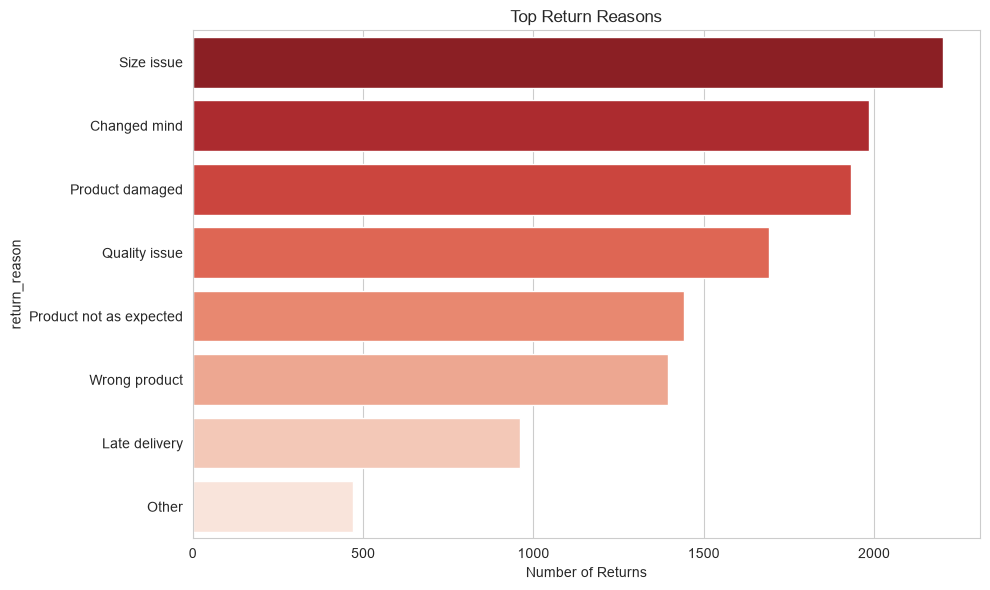


Returns by Category:
category
Fashion                   3185
Electronics               1232
Footwear                  1205
Home & Kitchen            1102
Appliances                 783
Bags                       692
Toys                       550
Health & Wellness          441
Grocery                    392
Books                      350
Beauty                     349
Mobile Accessories         331
Stationery                 321
Personal Care              266
Sports                     190
Furniture                  186
Watches                    117
Baby Care                  113
Musical Instruments         83
Automotive Accessories      73
Pet Supplies                69
Office Supplies             45
Name: count, dtype: int64


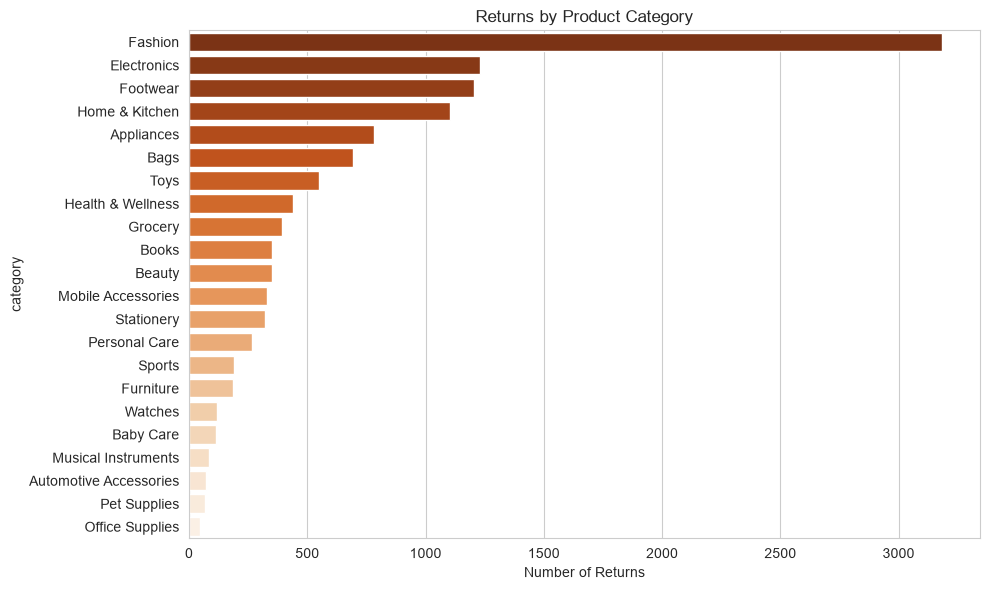

In [ ]:
# 2. Returns Analysis

print("\n" + "="*60)
print("RETURNS ANALYSIS")
print("="*60)

total_returns = returns.shape[0]
total_orders = orders['order_id'].nunique()
return_rate = (total_returns / total_orders) * 100

print(f"Total Returns     : {total_returns:,}")
print(f"Total Orders      : {total_orders:,}")
print(f"Overall Return Rate: {return_rate:.2f}%")


# --------- Return Reason --------

print("\nTop Return Reasons:")
returns_reasons = returns['return_reason'].value_counts()
print(returns_reasons)

plt.figure(figsize=(10, 6))
sns.barplot(x=returns_reasons.values, y=returns_reasons.index, palette='Reds_r', hue = returns_reasons.index)
plt.title("Top Return Reasons")
plt.xlabel("Number of Returns")
plt.tight_layout()
plt.show()


# -------- Returns by Category ------

returns_with_category = returns.merge(products[['product_id', 'category']], on='product_id', how='left')
category_returns = returns_with_category['category'].value_counts()

print("\nReturns by Category:")
print(category_returns)

plt.figure(figsize=(10, 6))
sns.barplot(x=category_returns.values, y=category_returns.index, palette='Oranges_r', hue=category_returns.index)
plt.title("Returns by Product Category")
plt.xlabel("Number of Returns")
plt.tight_layout()
plt.show()




DELIVERY PERFORMANCE ANALYSIS
On-time    52233
Delayed    37448
Name: count, dtype: int64


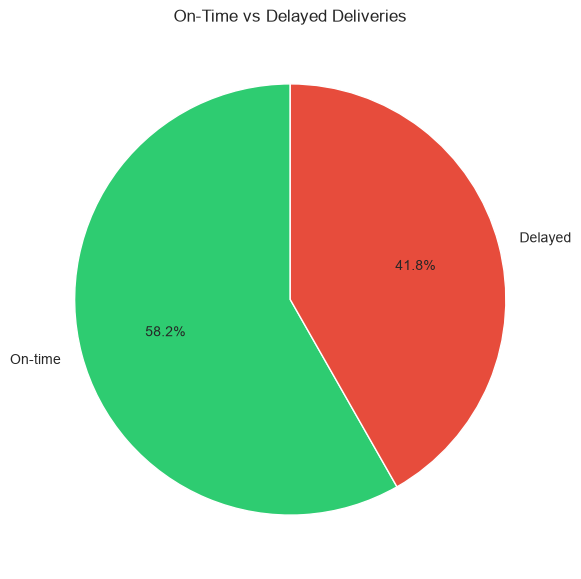


Average Delivery Delay: 0.39 days


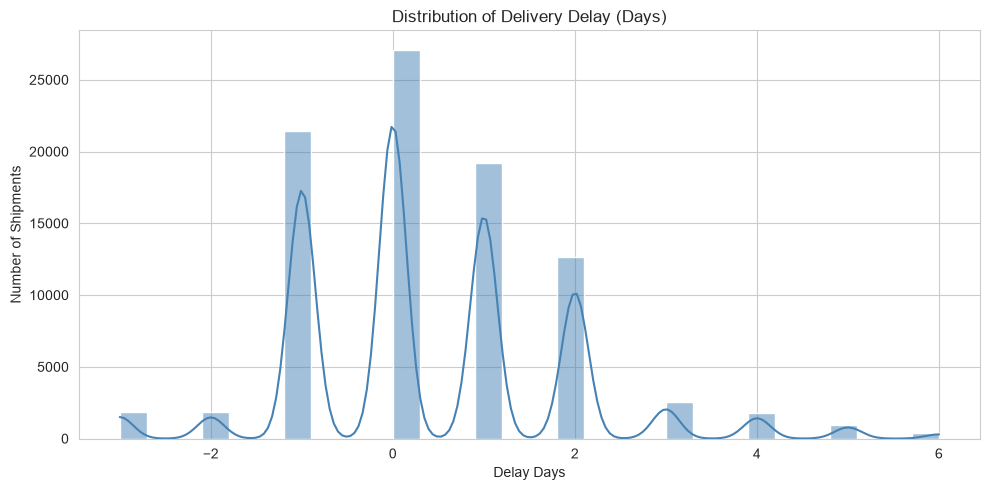

In [35]:
# 3. Delivery Performance Analysis

print("\n" + "="*60)
print("DELIVERY PERFORMANCE ANALYSIS")
print("="*60)

### Delayed vs On-time

delay_counts = shipments['delayed_flag'].value_counts()
delay_counts.index = ['On-time', 'Delayed']
print(delay_counts)

plt.figure(figsize=(7, 7))
plt.pie(delay_counts, labels=delay_counts.index, autopct='%1.1f%%', startangle=90, colors=['#2ecc71', '#e74c3c'])
plt.title("On-Time vs Delayed Deliveries")
plt.show()


### Average Delivary Delay

avg_delay = shipments['delivery_delay_days'].mean()
print(f"\nAverage Delivery Delay: {avg_delay:.2f} days")

# Delivery Delay Distribution
plt.figure(figsize=(10, 5))
sns.histplot(shipments['delivery_delay_days'], bins=30, kde=True, color='steelblue')
plt.title("Distribution of Delivery Delay (Days)")
plt.xlabel("Delay Days")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

In [37]:
# 4. Impact of Delay on Returns (simple Analysis)

print("\n" + "="*60)
print("DELAY vs RETURNS RELATIONSHIP")
print("="*60)

# Orders that were delayed
delayed_orders = shipments[shipments['delayed_flag'] == 1]['order_id']
delayed_returns = returns[returns['order_id'].isin (delayed_orders)]

print(f"Returns from Delayed Orders: {len(delayed_returns)}")
print(f"Total Returns              : {len(returns)}")
print(f"% of Returns from Delayed Orders: {len(delayed_returns)/len(returns)*100:.2f}%")


DELAY vs RETURNS RELATIONSHIP
Returns from Delayed Orders: 4990
Total Returns              : 12075
% of Returns from Delayed Orders: 41.33%


#### KEY INSIGHTS - RETURNS & DELIVERY

1. Overall return rate gives a clear picture of post-purchase issues.
2. Top return reasons help identify product or process problems.
3. Some categories have significantly higher return rates.
4. Delivery delays exist and should be monitored closely.
5. Delayed deliveries may contribute to higher returns.